# Visualization Hands-On
**Seminar 4: Mini-Project Sprint | CS 5045**

---

You have about 50 minutes for three rounds of practice, on a dataset you haven't seen before: every county in the United States, from the 2010 Census.

No scaffold in any of these cells, same "write it yourself" convention as the Code From Scratch assignment sections. Chart type, color, and labels are your calls to make and defend.

`Counties2010.csv`:

| Column | Meaning |
|---|---|
| Name | County name |
| State | Two-letter state code |
| Population | 2010 population |
| Pop2000 | 2000 population |
| IncomePerCapita | Income per capita, dollars |
| PercentCollegeGrad | Percent of adults with a college degree |
| MedianRent | Median monthly rent, dollars |
| CommuteTime | Mean commute time, minutes |
| LandArea | Land area, square miles |
| Region | US Census region: Northeast, Midwest, South, West |

Run the setup cell, then work through each round in order. The actual point of each round is the one-sentence conclusion at the end, not the chart itself.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Counties2010.csv")
df.head()

,Name,State,Population,Pop2000,IncomePerCapita,PercentCollegeGrad,MedianRent,CommuteTime,LandArea,Region
0,Aleutians East,AK,3141,2697,28942,12.5,475,4.5,6981.94,West
1,Aleutians West,AK,5561,5465,33318,8.5,1050,4.9,4390.28,West
2,Anchorage,AK,291826,260283,46243,32.3,921,18.0,1704.68,West
3,Bethel,AK,17013,16006,26990,14.4,845,6.7,40570.00,West
4,Bristol Bay,AK,997,1258,48747,14.2,687,9.2,503.84,West


## Round 1: Choosing a Chart Type (15 min)

Same dataset, three different questions. Each one has a chart type that fits it: your job is to pick it and be ready to say why, not to match a formula.
    - Answer: 

**1a.** What does the distribution of `IncomePerCapita` look like across all 3,146 counties? Symmetric? Skewed? Where does most of the data sit?
    -

**1b.** Which 10 states have the most counties in this dataset? Rank them.

**1c.** Is there a relationship between `PercentCollegeGrad` and `IncomePerCapita`? If so, how strong, and in which direction?

For each one: build a chart, then write a one-sentence answer as a comment.

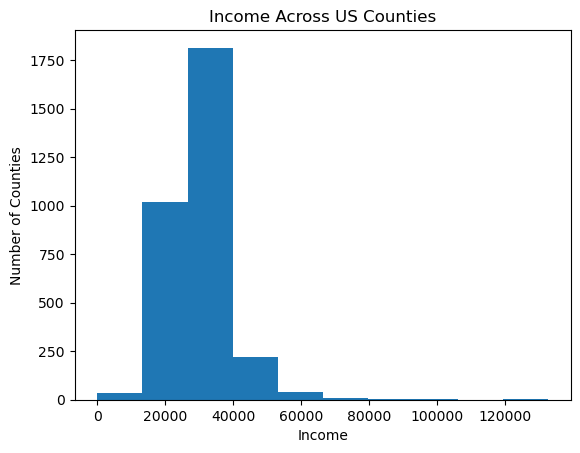

In [15]:
# 1a. Distribution of IncomePerCapita across all 3,146 counties.
# Build one chart. One-sentence answer as a comment below.
# A histogram shows how income values are distributed.
plt.figure()
plt.hist(df['IncomePerCapita'])
plt.title('Income Across US Counties')
plt.xlabel('Income')
plt.ylabel('Number of Counties')
plt.show()

# The distribution is right skewed. Most counties have lower to middle incomes with few much higher income counties.


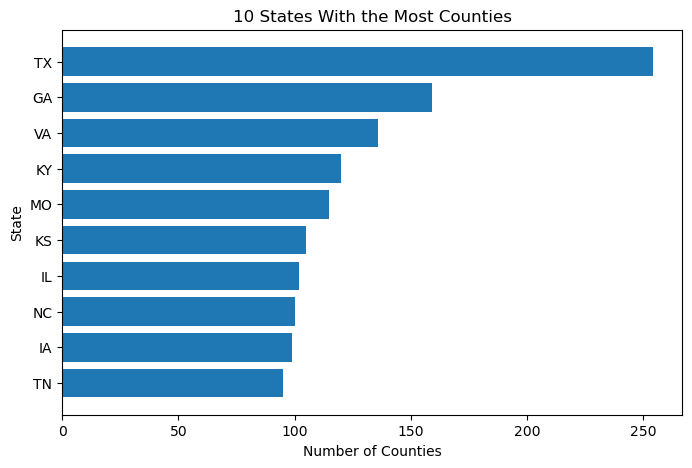

In [ ]:
# 1b. The 10 states with the most counties in this dataset, ranked.
# Build one chart. One-sentence answer as a comment below.
# A horizontal bar chart makes the state ranking easy to compare.
county_counts = df['State'].value_counts().head(10)
plt.figure(figsize=(8, 5))
plt.barh(county_counts.index, county_counts.values)
plt.gca().invert_yaxis()
plt.title('10 States With the Most Counties')
plt.xlabel('Number of Counties')
plt.ylabel('State')
plt.show()

# Texas has the most counties (254) then it's Georgia (159) and Virginia (136).

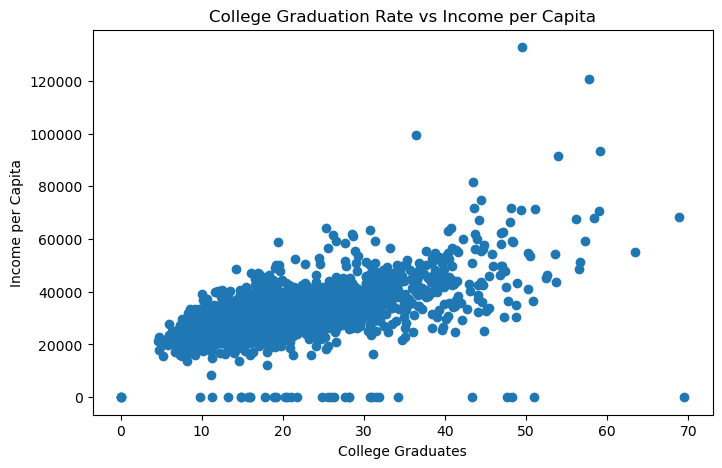

Correlation: (0.625674464166101, 3)


In [ ]:
# 1c. Relationship between PercentCollegeGrad and IncomePerCapita.
# Build one chart. One-sentence answer as a comment below.
# A scatter plot is useful for comparing two numerical variables.
plt.figure(figsize=(8, 5))
plt.scatter(df['PercentCollegeGrad'], df['IncomePerCapita'])
plt.title('College Graduation Rate vs Income per Capita')
plt.xlabel('College Graduates')
plt.ylabel('Income per Capita')
plt.show()
correlation = df['PercentCollegeGrad'].corr(df['IncomePerCapita'])
print('Correlation:', (correlation, 3))

# There is a moderately strong positive relationship with r = 0.626, so counties with more college graduates tend to have higher incomes.

## Round 2: Showing More Than Two Variables (20 min)

A single scatter plot only shows two numbers at once, unless you also use color and size to carry more.

**Task:**

1. Collapse the data to the state level. For each `State`, compute: the mean `PercentCollegeGrad`, the mean `IncomePerCapita`, the total `Population`, and its `Region`. (`groupby('State')` needs a different aggregation for each column: mean, mean, sum, first.)
2. Build ONE scatter plot with:
   - x = mean `PercentCollegeGrad`
   - y = mean `IncomePerCapita`
   - color = `Region`
   - size = total `Population`

Look for states that break the overall pattern: high education but only-average income, or the reverse. Write two sentences: what the overall relationship looks like, and name one state that doesn't fit it.

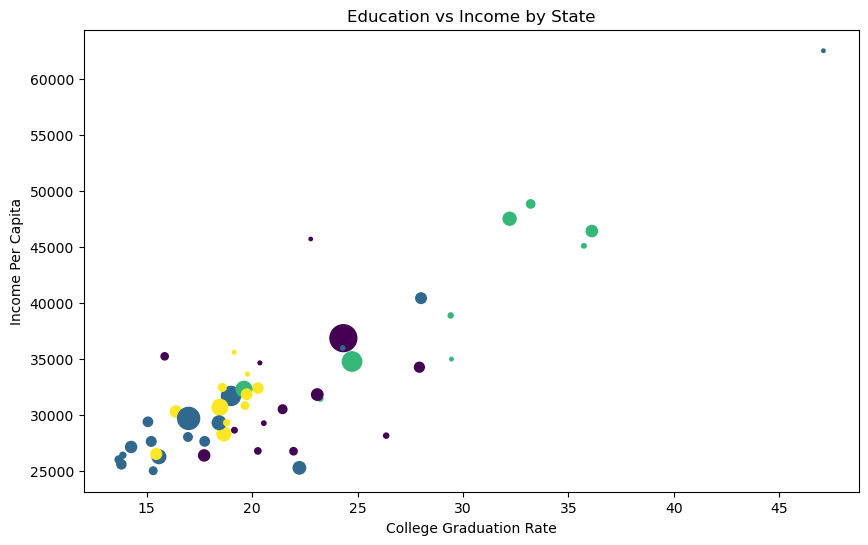

   State  PercentCollegeGrad  IncomePerCapita  Population     Region
7     DC           47.100000     62484.000000      601723      South
19    MA           36.114286     46411.785714     6547629  Northeast
39    RI           35.740000     45097.200000     1052567  Northeast
6     CT           33.212500     48829.875000     3574097  Northeast
31    NJ           32.214286     47512.857143     8791894  Northeast
46    VT           29.457143     34999.428571      625741  Northeast
30    NH           29.420000     38891.700000     1316470  Northeast
20    MD           28.012500     40431.666667     5773552      South
5     CO           27.934375     34279.437500     5029196       West
11    HI           26.360000     28181.600000     1360301       West


In [32]:
# 2. Aggregate to the state level (mean PercentCollegeGrad, mean IncomePerCapita,
# total Population, Region), then build one scatter with color = Region and
# size = Population. Two-sentence answer as a comment below.

state_data = df.groupby('State').agg({
    'PercentCollegeGrad': 'mean',
    'IncomePerCapita': 'mean',
    'Population': 'sum',
    'Region': 'first'
}).reset_index()

plt.figure(figsize=(10, 6))

plt.scatter(
    state_data['PercentCollegeGrad'],
    state_data['IncomePerCapita'],
    s=state_data['Population'] / 100000,
    c=pd.factorize(state_data['Region'])[0],
)

plt.xlabel('College Graduation Rate')
plt.ylabel('Income Per Capita')
plt.title('Education vs Income by State')
plt.show()

print(state_data.sort_values('PercentCollegeGrad', ascending=False).head(10))


# States with higher graduation rates generally have higher incomes.
# Population affects bubble size, while color represents region.

# Overall, states with higher average county graduation rates tend to have higher average county incomes.
# California has a relatively high average graduation rate but a less exceptional average county income than some similarly educated states.

## Round 3: Good Chart, Bad Chart (15 min)

**3a. Build the "bad" chart first, on purpose.**

Plot `Population` (x) against `IncomePerCapita` (y) for all 3,146 counties, as a plain scatter, no changes, no cleanup. Look at what happens.

**3b. Now fix it.**

You're asking the same question both charts are trying to answer: does a place's size relate to its income per person? This time:
- Think about what's distorting the first chart.
- Try a different unit of aggregation, a log scale, or filtering: whichever actually clears it up.
- Give the fixed version a title and labeled axes.

Write two sentences: what made the first chart unreadable, and what your fix actually changed about the story the data tells.

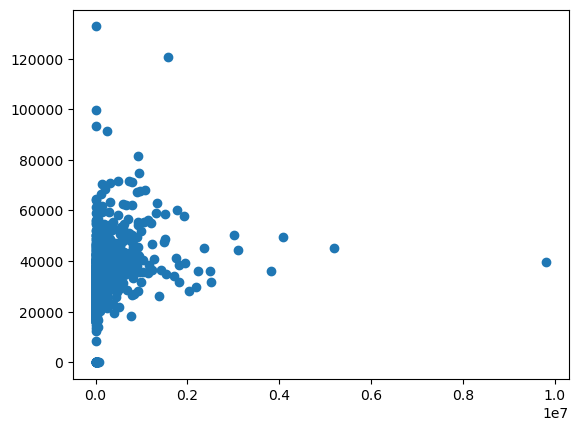

In [33]:
# 3a. The "bad" chart: Population vs IncomePerCapita, all 3,146 counties, no changes.
plt.scatter(df['Population'], df['IncomePerCapita'])
plt.show()


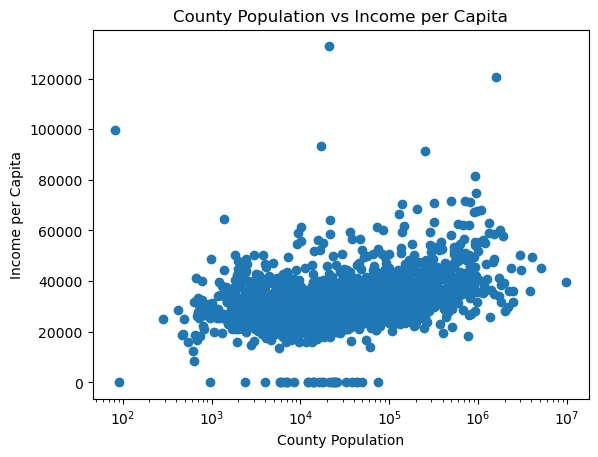

In [37]:
# 3b. Your fix. Same underlying question, a chart that actually answers it.
# Two-sentence answer as a comment below.
plt.figure()
plt.scatter(df['Population'], df['IncomePerCapita'])
plt.xscale('log')
plt.title('County Population vs Income per Capita')
plt.xlabel('County Population')
plt.ylabel('Income per Capita')
plt.show()

## Before the Sprint

You just made three real design decisions: which chart fits a question, how to layer in extra dimensions without making a mess, and how to tell when a chart is lying to you through clutter. That's exactly what Phase 4 of the sprint asks you to do on your own data, just once, not three times, and on a dataset you already know.